# **Introdução à Inteligência Artificial com TensorFlow e Keras**

Este notebook demonstra como construir e treinar uma rede neural simples para classificar dígitos escritos à mão usando o conjunto de dados MNIST.

## **Índice**

1. [Importar Bibliotecas Necessárias](#import)
2. [Carregar e Preparar o Conjunto de Dados MNIST](#data)
3. [Construir o Modelo](#model)
4. [Compilar o Modelo](#compile)
5. [Treinar o Modelo](#train)
6. [Avaliar o Modelo](#evaluate)
7. [Conclusão](#conclusion)


In [1]:
# Importar bibliotecas necessárias
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

## **2. Carregar e Preparar o Conjunto de Dados MNIST**
O conjunto de dados MNIST contém imagens de dígitos escritos à mão. Vamos carregá-lo e prepará-lo para o treinamento.

In [2]:
# Carregar o conjunto de dados MNIST
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Normalizar os dados de entrada
x_train = x_train.reshape(-1, 28 * 28).astype("float32") / 255
x_test = x_test.reshape(-1, 28 * 28).astype("float32") / 255

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## **Visualizar algumas imagens do conjunto de dados**

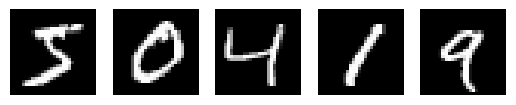

In [3]:
import matplotlib.pyplot as plt

# Exibir as primeiras 5 imagens do conjunto de treinamento
for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(x_train[i].reshape(28,28), cmap='gray')
    plt.axis('off')
plt.show()

## **3. Construir o Modelo**
Vamos criar um modelo sequencial simples com uma camada oculta.

In [4]:
# Criar o modelo
model = keras.Sequential([
    layers.Dense(128, activation='relu', input_shape=(28 * 28,)),
    layers.Dense(10, activation='softmax')
])

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## **4. Compilar o Modelo**
Antes de treinar o modelo, precisamos compilá-lo com um otimizador, uma função de perda e métricas.

In [5]:
# Compilar o modelo
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

## **5. Treinar o Modelo**
Agora, podemos treinar o modelo com os dados de treinamento.

In [6]:
# Treinar o modelo
model.fit(x_train, y_train, epochs=5, batch_size=32)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 6ms/step - accuracy: 0.8782 - loss: 0.4345
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 3ms/step - accuracy: 0.9648 - loss: 0.1188
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9777 - loss: 0.0763
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.9844 - loss: 0.0540
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.9865 - loss: 0.0444


## **6. Avaliar o Modelo**
Finalmente, avaliamos o modelo usando o conjunto de teste para ver sua performance em dados não vistos.

In [7]:
# Avaliar o modelo
test_loss, test_acc = model.evaluate(x_test, y_test)
print('\nAcurácia no conjunto de teste:', test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9727 - loss: 0.0823

Acurácia no conjunto de teste: 0.977400004863739


## **7. Conclusão**
Conseguimos construir e treinar uma rede neural simples para classificar dígitos escritos à mão com uma boa acurácia.

## 8. Carregar o Modelo Treinado

Se o modelo já foi treinado no mesmo notebook, não é necessário carregá-lo novamente. Porém, se o modelo foi salvo e você o quer carregar em um novo ambiente, você pode fazer o seguinte: